# 02 · 머신러닝 기초 — 회귀·분류 모델과 성능 평가
### 실습으로 배우는 신약개발 AI — 강의 목차 ④ 머신러닝 모델 유형과 성능 비교

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/02_ML_Basics_Regression_Classification.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 지도학습(회귀·분류) 개념 ② **회귀 성능지표**(MAE·RMSE·R²) ③ **분류 성능지표**(혼동행렬·정확도·정밀도·재현율·F1·ROC-AUC) ④ 여러 모델 비교 ⑤ 과대적합 |
| **데이터** | 회귀: ESOL 용해도(1,128 분자) · 분류: BBBP 혈액뇌장벽 투과(2,039 분자) — MoleculeNet 공개 |
| **실행 환경** | CPU · 약 15분 |

> 이 노트북은 이후 모든 예제의 **공통 기초**입니다. 모델을 만드는 것보다 **모델이 얼마나 좋은지 정확히 재는 것**이 더 중요합니다.

In [1]:
%pip install -q rdkit koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams['font.family'] = ['NanumGothic', 'DejaVu Sans']   # 한글 + 특수기호(², →) 대체 폰트
import warnings; warnings.filterwarnings("ignore")
from rdkit import Chem, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import Descriptors, Crippen
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


## 1. 머신러닝이란? — 데이터(X)로 정답(y)을 예측하는 함수 만들기
| 용어 | 의미 | 신약 예 |
|---|---|---|
| **X (특성, feature)** | 입력 — 분자를 표현한 숫자들 | 분자량, LogP, TPSA … |
| **y (레이블, target)** | 맞히고 싶은 정답 | 용해도 값, 독성 여부 |
| **모델** | X → y 관계를 데이터로부터 학습한 함수 | 선형회귀, 랜덤포레스트 … |
| **학습(fit)** | 손실함수를 줄이도록 파라미터를 조정 | `model.fit(X_train, y_train)` |
| **예측(predict)** | 처음 보는 X 에 대해 y 추정 | `model.predict(X_new)` |

### 지도학습의 두 가지 유형
| 유형 | y 의 형태 | 예 | 손실함수 | 대표 성능지표 |
|---|---|---|---|---|
| **회귀 (Regression)** | 연속된 숫자 | 용해도 logS = −3.2 | MSE | MAE, RMSE, **R²** |
| **분류 (Classification)** | 범주(클래스) | BBB 통과 O/X, 독성 有/無 | 크로스 엔트로피 | 정확도, 정밀도, 재현율, F1, **ROC-AUC** |

> **반드시 지킬 원칙**: 모델은 **학습 데이터(train)** 로 만들고, 성능은 **한 번도 보지 않은 평가 데이터(test)** 로 잰다.

## 2. 회귀 성능지표 — 손으로 먼저 계산해 보기
5개 화합물의 실제 용해도와 모델 예측값이 다음과 같다고 합시다.

| 지표 | 수식 | 의미 |
|---|---|---|
| **MAE** (평균절대오차) | $\frac{1}{n}\sum \lvert y_i-\hat y_i \rvert$ | 평균적으로 몇 단위 틀리나 (직관적) |
| **MSE** (평균제곱오차) | $\frac{1}{n}\sum (y_i-\hat y_i)^2$ | 큰 오차에 큰 벌점 — **학습 손실함수** |
| **RMSE** | $\sqrt{MSE}$ | MSE 를 원래 단위로 |
| **R²** (결정계수) | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | 1=완벽, 0=평균으로 찍은 수준, 음수=그보다 못함 |

In [2]:
y_true = np.array([-2.0, -3.5, -1.0, -4.2, -0.5])   # 실제 logS
y_pred = np.array([-2.4, -3.1, -1.3, -3.6, -0.9])   # 모델 예측

err = y_true - y_pred
mae  = np.mean(np.abs(err))
mse  = np.mean(err**2)
rmse = np.sqrt(mse)
r2   = 1 - np.sum(err**2) / np.sum((y_true - y_true.mean())**2)
print(f"손계산  MAE={mae:.3f}  MSE={mse:.3f}  RMSE={rmse:.3f}  R²={r2:.3f}")

# scikit-learn 함수로 같은 값이 나오는지 검증
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"sklearn MAE={mean_absolute_error(y_true, y_pred):.3f}  MSE={mean_squared_error(y_true, y_pred):.3f}  "
      f"RMSE={np.sqrt(mean_squared_error(y_true, y_pred)):.3f}  R²={r2_score(y_true, y_pred):.3f}")

손계산  MAE=0.420  MSE=0.186  RMSE=0.431  R²=0.907


sklearn MAE=0.420  MSE=0.186  RMSE=0.431  R²=0.907


## 3. 분류 성능지표 — 혼동행렬(Confusion Matrix)부터
강의 슬라이드의 예: 100개 분자 중 실제 독성(양성, p) 10개, 비독성(음성, n) 90개. 모델 결과:

| 실제 \ 예측 | 양성으로 예측 | 음성으로 예측 |
|---|---|---|
| **실제 양성** | TP = 7 | FN = 3 (놓침) |
| **실제 음성** | FP = 10 (오경보) | TN = 80 |

| 지표 | 수식 | 질문 |
|---|---|---|
| **정확도 Accuracy** | (TP+TN)/전체 | 전체 중 몇 개 맞혔나? |
| **정밀도 Precision** | TP/(TP+FP) | 양성이라고 한 것 중 진짜 양성은? (오경보 비용이 클 때) |
| **재현율 Recall (민감도)** | TP/(TP+FN) | 진짜 양성 중 몇 개를 찾아냈나? (놓치면 큰일일 때: 독성!) |
| **특이도 Specificity** | TN/(TN+FP) | 진짜 음성을 음성이라 한 비율 |
| **F1 점수** | 2·P·R/(P+R) | 정밀도와 재현율의 조화평균 |

In [3]:
TP, FN, FP, TN = 7, 3, 10, 80
acc  = (TP + TN) / (TP + FN + FP + TN)
prec = TP / (TP + FP)
rec  = TP / (TP + FN)
spec = TN / (TN + FP)
f1   = 2 * prec * rec / (prec + rec)
print(f"정확도={acc:.2f}  정밀도={prec:.2f}  재현율={rec:.2f}  특이도={spec:.2f}  F1={f1:.2f}")

# ⚠️ 불균형 데이터의 함정: '전부 음성'이라고 찍는 바보 모델의 정확도는?
print(f"전부 음성으로 찍어도 정확도 = {90/100:.2f}  (하지만 재현율 = 0 → 독성 물질을 하나도 못 찾음)")

정확도=0.87  정밀도=0.41  재현율=0.70  특이도=0.89  F1=0.52
전부 음성으로 찍어도 정확도 = 0.90  (하지만 재현율 = 0 → 독성 물질을 하나도 못 찾음)


## 4. 실제 데이터로 회귀 모델 — ESOL 용해도 예측
분자를 7개 기술자(descriptor)로 바꾸고(예제 01), **학습 80% / 평가 20%** 로 나눠 선형회귀를 학습합니다.

In [4]:
url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
esol = pd.read_csv(url).rename(columns={"measured log solubility in mols per litre": "logS"})

def featurize(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    return {"MolWt": Descriptors.MolWt(m), "LogP": Crippen.MolLogP(m), "TPSA": Descriptors.TPSA(m),
            "HBD": Descriptors.NumHDonors(m), "HBA": Descriptors.NumHAcceptors(m),
            "RotB": Descriptors.NumRotatableBonds(m), "AromRings": Descriptors.NumAromaticRings(m)}

X_reg = pd.DataFrame([featurize(s) for s in esol["smiles"]])
y_reg = esol["logS"]
print("X:", X_reg.shape, " y:", y_reg.shape)
X_reg.head()

X: (1128, 7)  y: (1128,)


,MolWt,LogP,TPSA,HBD,HBA,RotB,AromRings
0,457.432,-3.10802,202.32,7,12,7,1
1,201.225,2.84032,42.24,1,2,2,2
2,152.237,2.87800,17.07,0,1,4,0
3,278.354,6.29940,0.00,0,0,0,5
4,84.143,1.74810,0.00,0,1,0,1


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

Xtr, Xte, ytr, yte = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
lin = LinearRegression().fit(Xtr, ytr)          # 학습
pred = lin.predict(Xte)                          # 처음 보는 데이터로 예측

print(f"평가 데이터  MAE={mean_absolute_error(yte, pred):.3f}  RMSE={np.sqrt(mean_squared_error(yte, pred)):.3f}  R²={r2_score(yte, pred):.3f}")
print("\n선형회귀 계수 (특성 1단위 증가 시 logS 변화):")
print(pd.Series(lin.coef_, index=X_reg.columns).round(3))

평가 데이터  MAE=0.788  RMSE=1.054  R²=0.765

선형회귀 계수 (특성 1단위 증가 시 logS 변화):
MolWt       -0.005
LogP        -0.822
TPSA        -0.013
HBD         -0.079
HBA          0.193
RotB        -0.033
AromRings   -0.206
dtype: float64


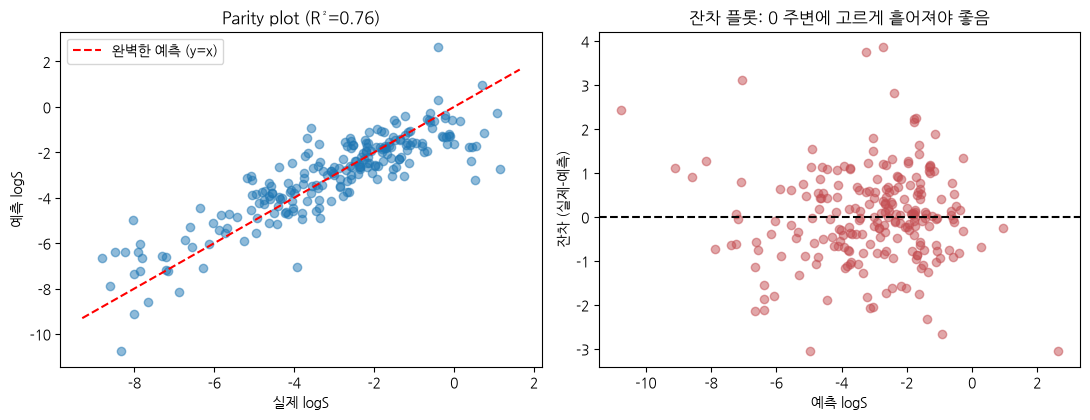

In [6]:
# 회귀 결과는 반드시 그림으로: ① 예측-실제 산점도(parity plot) ② 잔차(residual) 플롯
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].scatter(yte, pred, alpha=0.5)
lim = [yte.min() - 0.5, yte.max() + 0.5]
ax[0].plot(lim, lim, "r--", label="완벽한 예측 (y=x)")
ax[0].set_xlabel("실제 logS"); ax[0].set_ylabel("예측 logS"); ax[0].set_title(f"Parity plot (R²={r2_score(yte, pred):.2f})"); ax[0].legend()

resid = yte - pred
ax[1].scatter(pred, resid, alpha=0.5, color="#C44E52")
ax[1].axhline(0, color="k", ls="--")
ax[1].set_xlabel("예측 logS"); ax[1].set_ylabel("잔차 (실제-예측)"); ax[1].set_title("잔차 플롯: 0 주변에 고르게 흩어져야 좋음")
plt.tight_layout(); plt.show()

## 5. 실제 데이터로 분류 모델 — BBB(혈액뇌장벽) 투과 예측
치매·우울증 약은 **혈액뇌장벽(BBB)** 을 통과해야 합니다. 분자 구조로 **통과(1) / 미통과(0)** 를 예측합니다.

In [7]:
bbbp = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv")
feat = [featurize(s) for s in bbbp["smiles"]]
ok = [f is not None for f in feat]
X_cls = pd.DataFrame([f for f in feat if f is not None])
y_cls = bbbp.loc[ok, "p_np"].reset_index(drop=True)
print("분자 수:", len(X_cls), "  클래스 비율:", y_cls.value_counts(normalize=True).round(2).to_dict())

분자 수: 2039   클래스 비율: {1: 0.77, 0: 0.23}


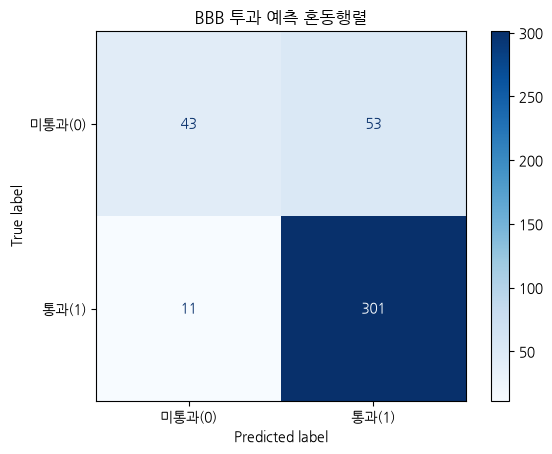

              precision    recall  f1-score   support

         미통과      0.796     0.448     0.573        96
          통과      0.850     0.965     0.904       312

    accuracy                          0.843       408
   macro avg      0.823     0.706     0.739       408
weighted avg      0.838     0.843     0.826       408



In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

# stratify=y : 학습/평가 세트의 클래스 비율을 동일하게 유지
Xtr, Xte, ytr, yte = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
proba = logit.predict_proba(Xte)[:, 1]        # 통과(1)일 확률
pred  = (proba >= 0.5).astype(int)            # 기본 임계값 0.5

ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["미통과(0)", "통과(1)"]).plot(cmap="Blues")
plt.title("BBB 투과 예측 혼동행렬"); plt.show()
print(classification_report(yte, pred, target_names=["미통과", "통과"], digits=3))

### ROC 곡선과 AUC — 임계값에 흔들리지 않는 성능 비교
- 분류 모델은 **확률(점수)** 을 출력하고, 임계값(보통 0.5)으로 O/X 를 정합니다.
- **ROC 곡선**: 임계값을 1→0 으로 내리며 (위양성률 FPR, 재현율 TPR) 을 그린 곡선
- **AUC**: ROC 곡선 아래 면적. 1.0=완벽, 0.5=동전 던지기. "양성 샘플에 더 높은 점수를 줄 확률"
- 불균형이 심하면 **PR 곡선(정밀도-재현율)** 도 함께 봅니다 (예제 04).

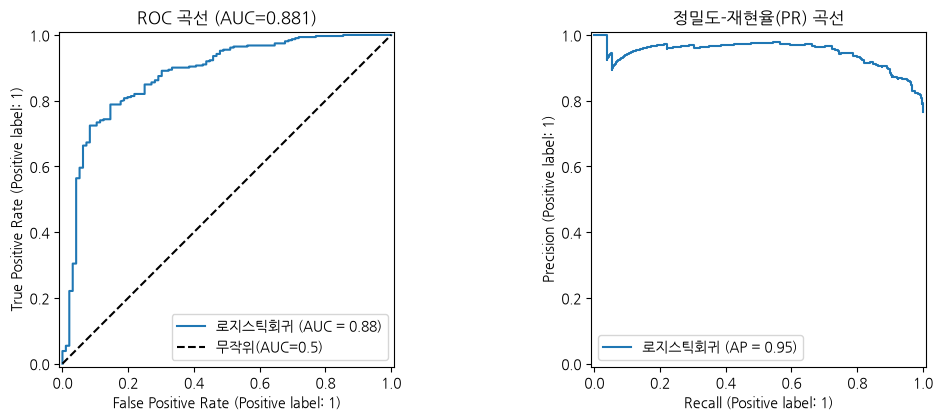

In [9]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
RocCurveDisplay.from_predictions(yte, proba, ax=ax[0], name="로지스틱회귀")
ax[0].plot([0, 1], [0, 1], "k--", label="무작위(AUC=0.5)"); ax[0].legend(); ax[0].set_title(f"ROC 곡선 (AUC={roc_auc_score(yte, proba):.3f})")
PrecisionRecallDisplay.from_predictions(yte, proba, ax=ax[1], name="로지스틱회귀"); ax[1].set_title("정밀도-재현율(PR) 곡선")
plt.tight_layout(); plt.show()

In [10]:
# 임계값을 바꾸면 정밀도와 재현율이 서로 '거래(trade-off)' 됩니다
rows = []
for th in [0.3, 0.5, 0.7, 0.9]:
    p = (proba >= th).astype(int)
    rows.append({"임계값": th, "정확도": accuracy_score(yte, p), "정밀도": precision_score(yte, p),
                 "재현율": recall_score(yte, p), "F1": f1_score(yte, p)})
pd.DataFrame(rows).round(3)

,임계값,정확도,정밀도,재현율,F1
0,0.3,0.826,0.823,0.984,0.896
1,0.5,0.843,0.850,0.965,0.904
2,0.7,0.831,0.879,0.904,0.891
3,0.9,0.510,0.967,0.372,0.537


> **현장 해석**: BBB 투과 약물을 찾는 1차 스크리닝이라면 좋은 후보를 놓치지 않도록 **재현율**을 중시(임계값↓),
> 비싼 동물실험 후보를 고를 때는 **정밀도**를 중시(임계값↑)합니다. **임계값은 업무 목적이 정합니다.**

## 6. ⭐ 머신러닝 모델 유형 비교 (강의 목차 ④)
| 계열 | 모델 | 특징 | 스케일링 |
|---|---|---|---|
| 선형 | 선형/릿지 회귀, 로지스틱 회귀 | 가중합으로 점수 계산, 해석 쉬움 | 필요 |
| 거리 기반 | k-최근접 이웃(kNN) | 가까운 샘플 k개의 평균/다수결 | 필요 |
| 마진 기반 | SVM / SVR | 클래스 간 간격(margin) 최대화 | 필요 |
| 트리 | 결정트리 | 예/아니오 질문의 반복, 시각화 쉬움 | 불필요 |
| 앙상블 | 랜덤포레스트, 그래디언트부스팅 | 수백 개 트리의 평균/누적, 대체로 강력 | 불필요 |

> 스케일링이 필요한 모델은 `make_pipeline(StandardScaler(), 모델)` 로 묶어 **평가 데이터 정보가 학습에 새지 않게(데이터 누수 방지)** 합니다.

In [11]:
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier)

reg_models = {
    "선형회귀": make_pipeline(StandardScaler(), LinearRegression()),
    "릿지회귀": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "SVR": make_pipeline(StandardScaler(), SVR(C=3)),
    "결정트리": DecisionTreeRegressor(max_depth=6, random_state=42),
    "랜덤포레스트": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "그래디언트부스팅": GradientBoostingRegressor(random_state=42),
}
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
reg_rows = []
for name, m in reg_models.items():
    p = m.fit(Xtr_r, ytr_r).predict(Xte_r)
    reg_rows.append({"모델": name, "MAE": mean_absolute_error(yte_r, p),
                     "RMSE": np.sqrt(mean_squared_error(yte_r, p)), "R²": r2_score(yte_r, p)})
reg_res = pd.DataFrame(reg_rows).sort_values("R²", ascending=False).round(3)
reg_res

,모델,MAE,RMSE,R²
2,kNN,0.563,0.806,0.862
6,그래디언트부스팅,0.575,0.811,0.861
5,랜덤포레스트,0.560,0.817,0.859
3,SVR,0.570,0.841,0.850
4,결정트리,0.727,1.003,0.787
1,릿지회귀,0.787,1.053,0.765
0,선형회귀,0.788,1.054,0.765


In [12]:
cls_models = {
    "로지스틱회귀": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "SVM": make_pipeline(StandardScaler(), SVC(C=3, probability=True, random_state=42)),
    "결정트리": DecisionTreeClassifier(max_depth=6, random_state=42),
    "랜덤포레스트": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "그래디언트부스팅": GradientBoostingClassifier(random_state=42),
}
cls_rows = []
for name, m in cls_models.items():
    m.fit(Xtr, ytr)
    pr = m.predict_proba(Xte)[:, 1]; p = (pr >= 0.5).astype(int)
    cls_rows.append({"모델": name, "정확도": accuracy_score(yte, p), "정밀도": precision_score(yte, p),
                     "재현율": recall_score(yte, p), "F1": f1_score(yte, p), "ROC-AUC": roc_auc_score(yte, pr)})
cls_res = pd.DataFrame(cls_rows).sort_values("ROC-AUC", ascending=False).round(3)
cls_res

,모델,정확도,정밀도,재현율,F1,ROC-AUC
4,랜덤포레스트,0.868,0.875,0.965,0.918,0.912
5,그래디언트부스팅,0.863,0.870,0.965,0.915,0.908
2,SVM,0.873,0.869,0.981,0.922,0.907
0,로지스틱회귀,0.843,0.850,0.965,0.904,0.881
1,kNN,0.892,0.904,0.962,0.932,0.872
3,결정트리,0.824,0.845,0.942,0.891,0.788


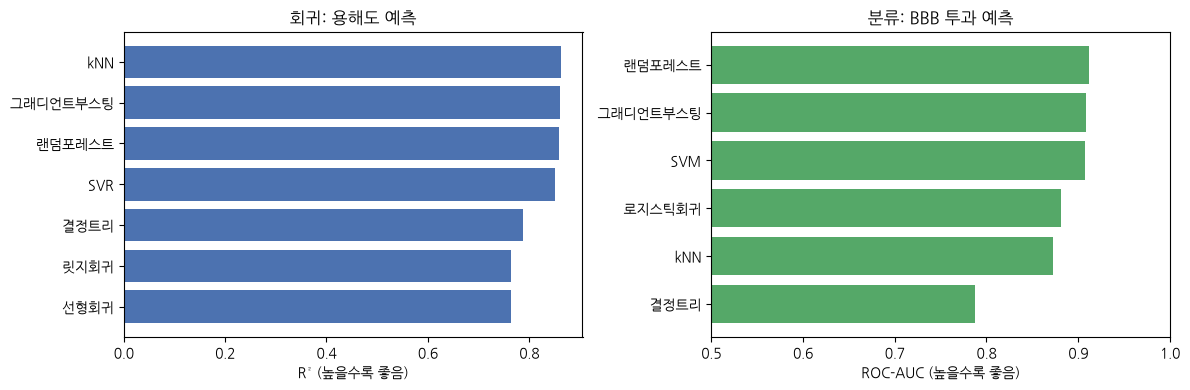

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(reg_res["모델"], reg_res["R²"], color="#4C72B0"); ax[0].invert_yaxis()
ax[0].set_xlabel("R² (높을수록 좋음)"); ax[0].set_title("회귀: 용해도 예측")
ax[1].barh(cls_res["모델"], cls_res["ROC-AUC"], color="#55A868"); ax[1].invert_yaxis()
ax[1].set_xlim(0.5, 1); ax[1].set_xlabel("ROC-AUC (높을수록 좋음)"); ax[1].set_title("분류: BBB 투과 예측")
plt.tight_layout(); plt.show()

## 7. 과대적합(Overfitting) — 학습 성능 vs 평가 성능
모델이 너무 복잡하면 학습 데이터를 '암기'해서 새 데이터에서는 오히려 못 맞힙니다.
결정트리의 깊이를 키우며 **학습 R²** 와 **평가 R²** 를 비교해 봅니다.

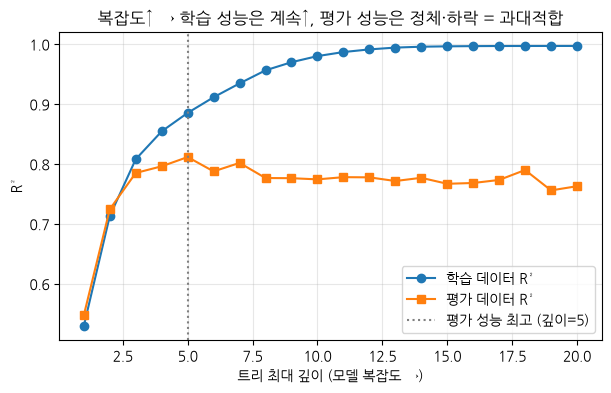

In [14]:
depths = range(1, 21)
tr_sc, te_sc = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(Xtr_r, ytr_r)
    tr_sc.append(r2_score(ytr_r, t.predict(Xtr_r))); te_sc.append(r2_score(yte_r, t.predict(Xte_r)))

plt.figure(figsize=(7, 4))
plt.plot(depths, tr_sc, "o-", label="학습 데이터 R²")
plt.plot(depths, te_sc, "s-", label="평가 데이터 R²")
best = int(np.argmax(te_sc)) + 1
plt.axvline(best, color="gray", ls=":", label=f"평가 성능 최고 (깊이={best})")
plt.xlabel("트리 최대 깊이 (모델 복잡도 →)"); plt.ylabel("R²"); plt.legend(); plt.grid(alpha=0.3)
plt.title("복잡도↑ → 학습 성능은 계속↑, 평가 성능은 정체·하락 = 과대적합")
plt.show()

> **과대적합 대처법**: 모델 단순화(깊이 제한·규제화), 데이터 추가, 앙상블, **교차검증으로 하이퍼파라미터 선택** (예제 06에서 심화)

## 🧪 LLM 코딩 과제
```
X_reg(분자 기술자 7개)와 y_reg(용해도)로 5-겹 교차검증(KFold, shuffle=True)을 수행해서
선형회귀와 랜덤포레스트의 R² 평균±표준편차를 비교하는 코드를 써줘. 결과는 상자그림(boxplot)으로 그려줘.
```

In [15]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 — 성능지표 치트시트
| 문제 | 지표 | 언제 중시? |
|---|---|---|
| 회귀 | **MAE** | 평균 오차를 직관적으로 설명할 때 |
| 회귀 | **RMSE** | 큰 오차가 치명적일 때 (MSE 는 학습 손실함수) |
| 회귀 | **R²** | 모델 간 설명력 비교 (1에 가까울수록) |
| 분류 | 정확도 | 클래스가 균형일 때만 의미 있음 |
| 분류 | **재현율** | 놓치면 안 될 때 (독성, 부작용, OOS) |
| 분류 | **정밀도** | 오경보 비용이 클 때 (고가 후속실험) |
| 분류 | F1 | 정밀도·재현율 균형 |
| 분류 | **ROC-AUC / PR-AUC** | 임계값과 무관한 모델 비교 / 불균형 데이터 |

➡️ **다음 예제 03**: 지문·전체 기술자로 **용해도 QSAR 모델**을 고도화하고, 적용 범위(Applicability Domain)를 배웁니다.